# Notebook 02: Target Definition

**Project:** Credit Decision Assistant

## What this notebook is for

Every prediction model learns from examples where the answer is already known. That known answer is called the **target**. Here it's a yes/no flag on each loan saying whether the borrower got into serious trouble. Everything the model learns, and every probability it later gives, depends on how this flag is defined. A badly defined target produces a model that confidently predicts the wrong thing.

Notebook 01 showed that the obvious target, *"did this loan eventually get written off?"* measured only on loans that have already finished, gives results that depend on how old the loans were when the data was taken. So this notebook builds a target that asks **the same question of every loan, over the same window of time**:

> **Did the borrower seriously stop paying within the first 12 months of the loan?**

A loan that has been running for at least 12 months can answer this whether it has finished or not. That makes loans from different years directly comparable.

## A few terms used in this notebook

| Term | What it means here |
|---|---|
| **Months on book** | How many months have passed since the loan was given out. |
| **Days past due** | How late a payment is. "90 days past due" means about three monthly payments have been missed in a row. |
| **Default** | In this project: the borrower reached 90 days past due within the first 12 months and never caught up. |
| **Charged off** | Lending Club gave up on collecting the loan and wrote it off as a loss, roughly five months after payments stopped. |
| **Class imbalance** | When one answer is much rarer than the other. Here, defaults are about 1 loan in 28. |

## What this notebook produces

- `data/processed/target_12m.parquet`: one row per eligible loan with its 12-month default flag, plus two alternative versions of the flag for later robustness checks.
- An updated `data/interim/audit_config.json` that records exactly how the target was defined.

## Setup

Load the settings saved in Notebook 01 (the snapshot date and the scope decisions) and the loan index. Two constants define the target:
- `HORIZON_M = 12`: we look at the first 12 months of each loan.
- `DPD_LAG_M = 3`: a borrower counts as defaulted once three monthly payments have been missed, which is the usual 90-days-past-due rule.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

PROJECT_ROOT  = Path.cwd().parent
INTERIM_DIR   = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"     # model-ready data starts here
FIG_DIR       = PROJECT_ROOT / "outputs" / "figures"

# Settings decided in Notebook 01 (snapshot date, scope decisions)
with open(INTERIM_DIR / "audit_config.json") as f:
    config = json.load(f)

SNAPSHOT  = pd.Timestamp(config["snapshot"] + "-01")   # March 2019
HORIZON_M = 12      # the question: default within the first 12 months
DPD_LAG_M = 3       # 90 days overdue is about 3 missed monthly payments

# One row per real loan, with dates and status (built in Notebook 01)
loans = pd.read_parquet(INTERIM_DIR / "loan_index.parquet")
print(f"Snapshot: {SNAPSHOT:%b-%Y} | loans loaded: {len(loans):,}")

Snapshot: Mar-2019 | loans loaded: 2,260,668


## Step 1: Which loans can answer the question?

A loan can only answer "did this go wrong within 12 months?" if we have watched it for at least 12 months. With the data taken in March 2019, that means the loan must have been issued **in March 2018 or earlier**.

Two more rules come from Notebook 01:
- **Issued from 2013 onwards**, because important credit history fields are only complete from 2013.
- **Individual applications only**, because joint applications barely exist in the earlier years the model will learn from.

**Result:**
- **1,709,332 loans qualify**, about 76% of the data.
- The biggest group removed is the 387,378 loans less than 12 months old, which simply haven't had a full year yet. The other two rules remove far fewer (the counts overlap, so they don't add up to the total removed).
- Among the qualifying loans, 489,389 are still being repaid. With the old "finished loans only" approach they would have been thrown away. Here they stay in, which is exactly what removes the timing problem found in Notebook 01.

In [2]:
scope = config["scope"]
# A loan needs 12 full months before the snapshot, so the latest usable issue month is March 2018
last_eligible_issue = SNAPSHOT - pd.DateOffset(months=HORIZON_M)

in_scope = (
    (loans["issue_year"] >= scope["min_issue_year"]) &                  # 2013 onwards
    (loans["application_type"] == scope["application_type"]) &          # individual applications
    (loans["issue_d"] <= last_eligible_issue)                           # at least 12 months old
)
print(f"Last eligible issue month: {last_eligible_issue:%b-%Y}")
print(f"Eligible loans: {in_scope.sum():,} of {len(loans):,}")

# How many each rule removes (they overlap, so these won't add up exactly)
print(f"  issued before {scope['min_issue_year']}:  {(loans['issue_year'] < scope['min_issue_year']).sum():,}")
print(f"  joint applications:    {(loans['application_type'] != scope['application_type']).sum():,}")
print(f"  less than 12 months old: {(loans['issue_d'] > last_eligible_issue).sum():,}")

pop = loans.loc[in_scope].copy()     # the population we model from here on
print("\nStatus at snapshot, eligible loans:")
print(pop["loan_status"].value_counts().to_string())

Last eligible issue month: Mar-2018
Eligible loans: 1,709,332 of 2,260,668
  issued before 2013:  95,902
  joint applications:    120,710
  less than 12 months old: 387,378

Status at snapshot, eligible loans:
loan_status
Fully Paid            952531
Current               489389
Charged Off           244081
Late (31-120 days)     14982
In Grace Period         5508
Late (16-30 days)       2809
Default                   32


## Step 2: Build the 12-month default flag

The data doesn't contain a month-by-month payment history. It only tells us **the month of the last payment received** (`last_pymnt_d`). That's enough to work out when payments stopped.

**1. First missed payment.** If the last payment arrived in month 7 of the loan, payment 8 was the first one missed:

$$\text{first missed month} = \text{months from issue to last payment} + 1$$

Borrowers who never paid anything get first missed month = 1.

**2. When does missing payments become a default?** One late payment is often a slip, like a forgotten direct debit. Three missed in a row (90 days) is a real sign the borrower can't pay, and it's the threshold lenders and regulators commonly use. So the default happens three months after the first missed payment, and for that to fall within the first 12 months:

$$\text{first missed month} + 3 \le 12 \quad\Longleftrightarrow\quad \text{first missed month} \le 9$$

**3. The borrower must not have recovered.** The loan must have been **charged off**, or still be **seriously late** at the snapshot ("Late (31-120 days)" or "Default"). Someone who missed a payment but then caught up made later payments, so their last payment date is recent and they won't be flagged. That's intended: they recovered.

Putting it together:

$$\text{default\_12m} = 1 \quad \text{if (charged off or seriously late) and first missed month} \le 9, \quad \text{otherwise } 0$$

Everything else counts as 0: loans still being repaid on time, loans paid off early, and loans that only went wrong **after** their first year. For a 12-month question, they all correctly count as "didn't default in the first 12 months".

**Result:**
- **12-month default rate: 3.52%** (60,135 of 1,709,332 loans).
- That's much lower than the 13% to 15% lifetime rates in Notebook 01, and it should be. Of the 244,081 charged-off loans in this group, only about a quarter went wrong in their first year. Most defaults happen later in a loan's life, and this question deliberately covers year one only.
- **Only serious statuses appear among the defaults:** 60,015 Charged Off, 119 Late (31-120 days) and 1 Default. Only 119 of the 14,982 seriously late loans count, because most of them fell behind recently, long after their first year.
- **The first missed month among defaults runs from 1 to 9** (typically month 6), exactly as the rule intends.

In [3]:
# First missed payment month: one month after the last payment (month 1 if they never paid)
pop["first_missed_m"] = (pop["months_to_last_pymnt"].fillna(0) + 1).astype("int16")

# Statuses that mean the borrower really stopped paying (not just a few days late)
SERIOUS = {"Charged Off", "Late (31-120 days)", "Default"}
pop["serious_bad"] = pop["loan_status"].isin(SERIOUS)

# Default within 12 months: seriously bad AND 90 days overdue by month 12 (first miss by month 9)
pop["default_12m"] = (pop["serious_bad"] & (pop["first_missed_m"] + DPD_LAG_M <= HORIZON_M)).astype("int8")

print(f"12-month default rate: {pop['default_12m'].mean():.2%}  "
      f"({pop['default_12m'].sum():,} of {len(pop):,} loans)")

# Sanity check 1: only the serious statuses should ever be flagged
print("\nDefaults by status (only seriously bad statuses should appear):")
print(pop.loc[pop["default_12m"] == 1, "loan_status"].value_counts().to_string())
# Sanity check 2: by construction the first missed month must be between 1 and 9
print("\nFirst missed month among defaults (should run from 1 to 9):")
print(pop.loc[pop["default_12m"] == 1, "first_missed_m"].describe().round(1).to_string())

12-month default rate: 3.52%  (60,135 of 1,709,332 loans)

Defaults by status (only seriously bad statuses should appear):
loan_status
Charged Off           60015
Late (31-120 days)      119
Default                   1

First missed month among defaults (should run from 1 to 9):
count   60,135.0000
mean         6.2000
std          2.2000
min          1.0000
25%          5.0000
50%          6.0000
75%          8.0000
max          9.0000


## Step 3: Is the rate comparable across years?

The whole point of a fixed 12-month window is that every year's loans are measured the same way. This chart checks that, by issue quarter and split by loan term. It also checks for a possible flaw at the right-hand edge: loans issued in early 2018 have only just reached 12 months, and if their late payments hadn't shown up in the status yet, their rate would dip artificially in the last quarter or two.

**Result:**
- **No dip at the edge.** The last point (2018 Q1, 3.62%) sits right next to 2017 Q4. Over 2017 and 2018 the 36-month line falls while the 60-month line rises. A measurement problem at the edge would push both lines down together, so these movements are real changes in who was borrowing, not an artefact. No extra buffer is needed.
- **The risk level changed over time:**

| Issue year | 12-month default rate |
|---|---|
| 2013 | 2.65% |
| 2014 | 2.88% |
| 2015 | 3.39% |
| 2016 | 4.01% |
| 2017 | 3.77% |
| 2018 (Q1 only) | 3.62% |

  Lending got riskier from 2013 to a peak in mid-2016, then eased. That matches Notebook 01, where the lifetime default rate of fully finished 36-month loans rose from 12.7% to 14.9% between 2013 and 2015. Two different measurements pointing the same way is good evidence the target behaves sensibly. The easing after 2016 fits Lending Club's shift towards safer A and B grade borrowers seen in Notebook 01.
- **60-month loans default more than 36-month loans in every single quarter**, usually by 1 to 1.5 percentage points.

**Why this matters later:** because the overall default rate moves from year to year, a model trained on 2013 to 2015 loans (around 3.1%) and tested on later ones (around 3.9%) will tend to underestimate the overall level of risk, even if it ranks borrowers correctly. Notebook 03 will therefore keep a separate validation period to adjust the overall probability level. That adjustment is called **calibration**: making sure that when the model says "4%", about 4% of those borrowers really do default.

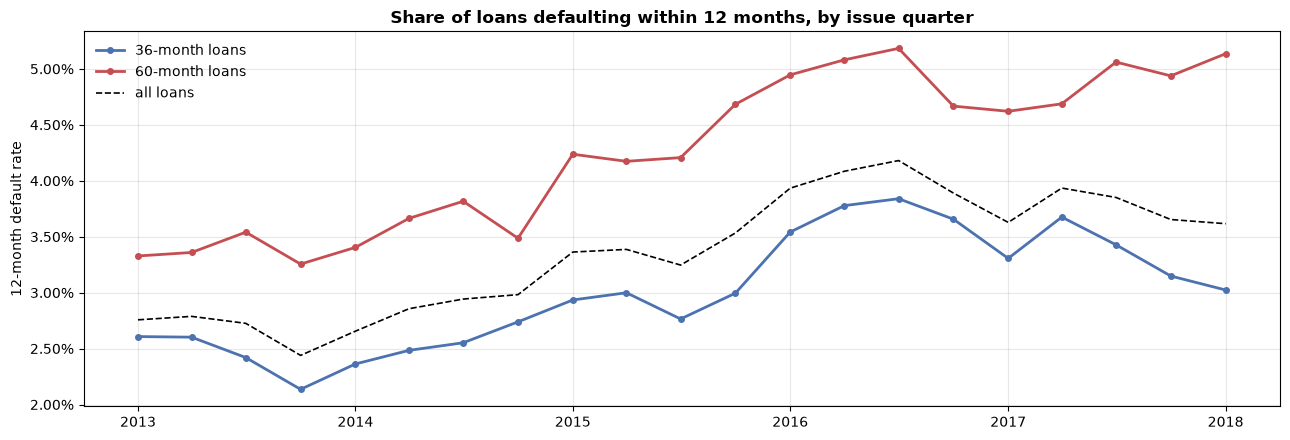

,rate,n_loans,defaults
issue_year,,,
2013,2.65%,"134,814","3,575"
2014,2.88%,"235,629","6,779"
2015,3.39%,"420,584","14,259"
2016,4.01%,"425,618","17,088"
2017,3.77%,"401,154","15,124"
2018,3.62%,"91,533","3,310"


In [4]:
# Group loans by the quarter they were issued in
pop["issue_q"] = pop["issue_d"].dt.to_period("Q").dt.to_timestamp()

# Default rate per quarter, separately for 36- and 60-month loans, plus the overall rate
by_q = pop.groupby(["issue_q", "term_m"])["default_12m"].agg(rate="mean", n="size").reset_index()
overall_q = pop.groupby("issue_q")["default_12m"].mean()

fig, ax = plt.subplots(figsize=(13, 4.5))
for term, color in [(36, "#4C72B0"), (60, "#C44E52")]:
    d = by_q[by_q["term_m"] == term]
    ax.plot(d["issue_q"], d["rate"], marker="o", ms=4, lw=2, color=color, label=f"{term}-month loans")
ax.plot(overall_q.index, overall_q.values, color="black", ls="--", lw=1.2, label="all loans")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Share of loans defaulting within 12 months, by issue quarter", fontweight="bold")
ax.set_ylabel("12-month default rate")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_default_12m_by_quarter.png", dpi=150)
plt.show()

# The same by year, with the number of loans and defaults behind each rate
yearly = pop.groupby("issue_year")["default_12m"].agg(rate="mean", n_loans="size", defaults="sum")
display(yearly.style.format({"rate": "{:.2%}", "n_loans": "{:,}", "defaults": "{:,}"}))

## Step 4: Does the "three missed payments" choice change the story?

The 90-day rule is a convention, not a law of nature. To check that the conclusions don't hinge on it, I compared three versions of "stopped paying":

| Version | Rule | Plain meaning |
|---|---|---|
| Lenient | first missed payment by month 12 | Fell behind at any point in year one and never recovered |
| **Chosen** | first missed payment by month 9 | 90 days overdue within year one |
| Strict | first missed payment by month 7 | About 150 days overdue within year one, roughly when Lending Club writes the loan off |

If all three put the years in the same order, the choice changes the level of the numbers but not the story.

To compare the orderings I used the **rank correlation** (Spearman's $\rho$). Each year is ranked from riskiest to safest under each version, and the rankings are compared:

$$\rho = 1 - \frac{6 \sum d^2}{n(n^2 - 1)}$$

where $d$ is the difference between a year's two ranks and $n$ is the number of years. A value of 1 means the two rankings are identical.

**Result:**
- **The level changes but the story doesn't.** Overall rates are 5.47%, 3.52% and 2.31%, yet every version shows the same rise from 2013 to a 2016 peak and then a slight easing. The versions also stay roughly in proportion: the chosen rate is about 62% to 67% of the lenient rate in every year.
- **"Chosen" and "strict" rank the six years identically** ($\rho = 1.000$). "Lenient" differs by a single swap of two neighbouring years, 2015 and 2018, whose rates are close in every version. With six years, one swap of neighbours gives $\rho = 1 - \frac{6 \times 2}{6 \times 35} = 0.943$, the smallest disagreement possible.
- Six yearly points is light evidence on its own. A stronger version of this check comes later, once there's a model: train on one definition and see whether it ranks borrowers the same way under the others.

**Why keep the chosen (90-day) version:**
- It's the definition lenders commonly use, so it's easy to explain and defend.
- The **lenient** version also flags people who only just fell behind near month 12, some of whom would have recovered, which adds noise.
- The **strict** version leans on the write-off timing that Notebook 01 found to be the least reliable piece of information, and it throws away about a third of the defaults the model would learn from.

In [5]:
# How many months after the first missed payment the default is counted, for each version
variants = {"lenient (miss by m12)": 0, "chosen (miss by m9)": DPD_LAG_M, "strict (miss by m7)": 5}

# Default rate by issue year under each version
sens = pd.DataFrame({
    name: (pop["serious_bad"] & (pop["first_missed_m"] + lag <= HORIZON_M)).groupby(pop["issue_year"]).mean()
    for name, lag in variants.items()
})
# Plus the overall rate across all years
sens.loc["all years"] = [
    (pop["serious_bad"] & (pop["first_missed_m"] + lag <= HORIZON_M)).mean() for lag in variants.values()
]
display(sens.style.format("{:.2%}"))

# Do the versions rank the years the same way? (1.0 = identical ordering)
print("Rank correlation between variants across years:")
print(sens.drop(index="all years").corr(method="spearman").round(3).to_string())

,lenient (miss by m12),chosen (miss by m9),strict (miss by m7)
issue_year,,,
2013,4.25%,2.65%,1.72%
2014,4.65%,2.88%,1.86%
2015,5.42%,3.39%,2.14%
2016,6.18%,4.01%,2.63%
2017,5.68%,3.77%,2.58%
2018,5.37%,3.62%,2.47%
all years,5.47%,3.52%,2.31%


Rank correlation between variants across years:
                       lenient (miss by m12)  chosen (miss by m9)  strict (miss by m7)
lenient (miss by m12)                 1.0000               0.9430               0.9430
chosen (miss by m9)                   0.9430               1.0000               1.0000
strict (miss by m7)                   0.9430               1.0000               1.0000


## Step 5: Save the target

The target table keeps one row per eligible loan with the chosen flag (`default_12m`) and the two alternative versions, so the robustness check can be repeated later without rebuilding anything. The exact definition is also written into the config file, so later notebooks read it rather than retyping it.

**Result:** 1,709,332 loans saved, with 60,135 defaults and 1,649,197 non-defaults.

**About the imbalance:** only about **1 loan in 28** is a default. That's normal for lending data and doesn't need "fixing" by copying defaults or deleting good loans. Those tricks distort the probabilities, and probabilities are exactly what the decision engine later needs. What the imbalance does change is how models are judged. Plain accuracy is useless here, because a model that predicts "no default" for everyone would be 96.5% accurate and completely worthless. Later notebooks therefore measure how well a model **ranks** risky borrowers above safe ones, and how **accurate its probabilities** are.

In [6]:
# Keep the alternative definitions too, for robustness checks later
pop["default_12m_lenient"] = (pop["serious_bad"] & (pop["first_missed_m"] <= HORIZON_M)).astype("int8")
pop["default_12m_strict"]  = (pop["serious_bad"] & (pop["first_missed_m"] + 5 <= HORIZON_M)).astype("int8")

TARGET_COLS = [
    "id", "issue_d", "issue_year", "term_m", "loan_amnt", "loan_status",
    "first_missed_m", "default_12m", "default_12m_lenient", "default_12m_strict",
]
target = pop[TARGET_COLS].reset_index(drop=True)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
target_path = PROCESSED_DIR / "target_12m.parquet"
target.to_parquet(target_path, index=False)

# Record the definition so later notebooks read it instead of retyping it
config["target"] = {
    "name": "default_12m",
    "definition": "Charged Off or 31+ days late at snapshot, with first missed payment by month 9 "
                  "(i.e. 90 days overdue within the first 12 months on book)",
    "horizon_months": HORIZON_M,
    "dpd_lag_months": DPD_LAG_M,
    "eligible_issue_from": f"{scope['min_issue_year']}-01",
    "eligible_issue_to": last_eligible_issue.strftime("%Y-%m"),
    "n_loans": int(len(target)),
    "default_rate": round(float(target["default_12m"].mean()), 5),
}
with open(INTERIM_DIR / "audit_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(f"Saved {target_path.name}: {len(target):,} loans | default rate {target['default_12m'].mean():.2%}")
print(f"Class balance: {target['default_12m'].value_counts().to_dict()}")

Saved target_12m.parquet: 1,709,332 loans | default rate 3.52%
Class balance: {0: 1649197, 1: 60135}


## Findings

1. **The target is: did the borrower reach 90 days overdue within the first 12 months and never recover?** Every loan observed for at least 12 months can answer it, including loans still being repaid, so loans from different years are measured the same way.
2. **1,709,332 loans qualify** (issued January 2013 to March 2018, individual applications), and **3.52% of them default** within 12 months.
3. **The rate changes over time:** from 2.65% for 2013 loans to a peak of 4.01% for 2016, then easing to about 3.6% to 3.8%. This agrees with the lifetime default rates measured in Notebook 01. 60-month loans default more than 36-month loans in every quarter.
4. **There is no sign of a measurement problem for the most recent loans**, so March 2018 stays as the last usable issue month.
5. **The 90-day choice changes the level but not the story.** Lenient and strict versions rank the years the same way (or differ by one swap of two close years), and they stay roughly in proportion to each other.
6. **Defaults are rare (about 1 in 28)**, so models will be judged on how well they rank borrowers and how accurate their probabilities are, not on accuracy.

## Limitations

- **Default timing comes from the last payment date only.** If a borrower missed payments, paid once more and then stopped for good, their default is dated slightly later than it really happened. Only a month-by-month payment history could fix this. It is uncommon, and it can only make the default rate a little lower, never higher.
- **Borrowers who fell behind but later caught up are counted as non-defaults**, even if they were briefly 90 days overdue. Without payment history these cases can't be seen. For a lender that's arguably the right outcome, since the money was eventually repaid.

**Next:** Notebook 03 applies the scope decisions, keeps only information available when someone applies for a loan, and splits the data by time into training, validation and test sets.